In [1]:
import sys
sys.path.append("../src")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL

from series import load_monthly_revenue

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

In [6]:
y = load_monthly_revenue()

print("Months:", len(y), "| from", y.index.min().date(), "to", y.index.max().date())
print("Missing values:", int(y.isna().sum()), "| frequency:", y.index.freqstr)
print("Total revenue:", round(y.sum(), 2))
print("Last 12 months:", round(y.tail(12).sum(), 0))
print("First value:", round(y.iloc[0], 0), "| Dec 2019:", round(y["2019-12-01"], 0))
assert len(y) == 61 and y.isna().sum() == 0

Months: 61 | from 2016-01-01 to 2021-01-01
Missing values: 0 | frequency: MS
Total revenue: 55229212.69
Last 12 months: 7738703.0
First value: 649919.0 | Dec 2019: 2477296.0


In [3]:
# If seasonal swings grow with the level of the business, a log transform is justified.
rows = []
for yr in range(2016, 2021):
    sub = y[str(yr)]
    mean_m = sub.mean()
    dec = y[f"{yr}-12-01"]
    rows.append({"year": yr, "avg_month": mean_m, "december": dec,
                 "dec_minus_avg": dec - mean_m, "dec_over_avg": dec / mean_m})
print(pd.DataFrame(rows).round(2).to_string(index=False))

 year    avg_month     december  dec_minus_avg  dec_over_avg
 2016   578,899.46   998,403.46     419,504.00          1.72
 2017   618,451.86 1,287,177.07     668,725.21          2.08
 2018 1,065,746.72 2,082,206.04   1,016,459.32          1.95
 2019 1,522,031.87 2,477,295.85     955,263.98          1.63
 2020   774,552.68   651,526.44    -123,026.24          0.84


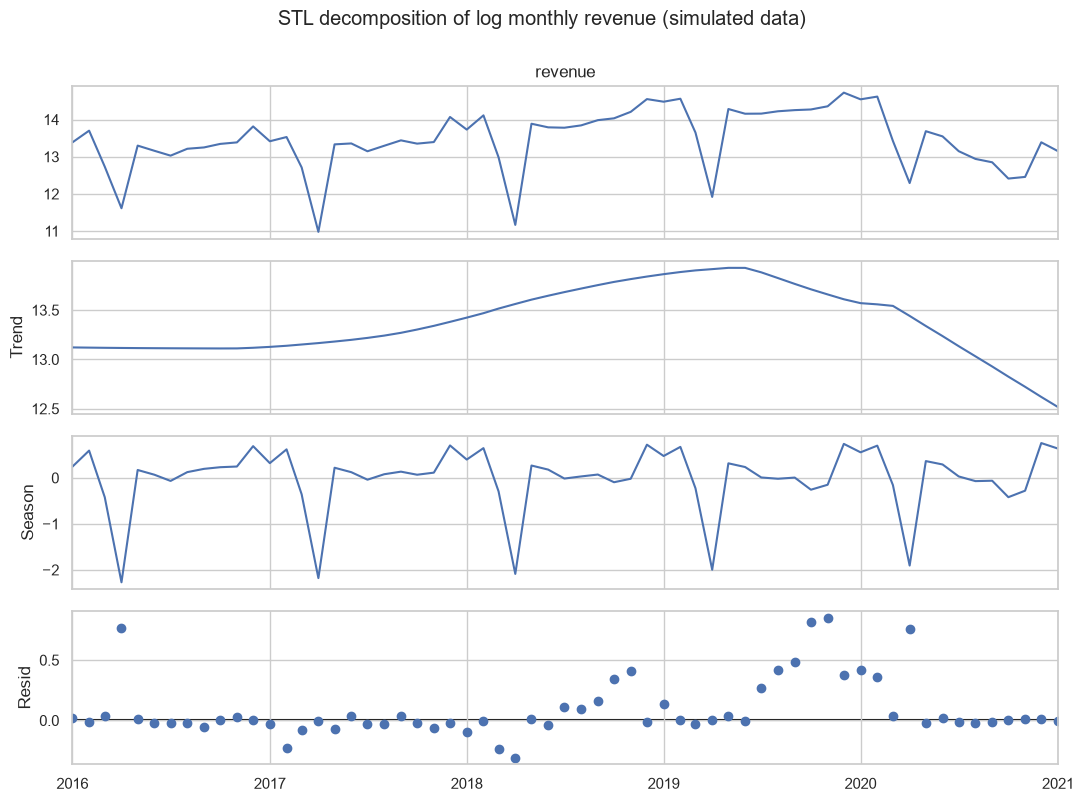

      mean    min    max
Jan 156.00 127.00 189.00
Feb 191.00 181.00 201.00
Mar  75.00  66.00  85.00
Apr  12.00  10.00  15.00
May 131.00 119.00 144.00
Jun 120.00 107.00 134.00
Jul  98.00  94.00 103.00
Aug 103.00  93.00 113.00
Sep 108.00  94.00 122.00
Oct  93.00  66.00 126.00
Nov 100.00  76.00 128.00
Dec 206.00 199.00 213.00

Residual std (log scale): 0.244 | log-series std: 0.797
Residuals beyond 2 std: ['2016-04', '2019-10', '2019-11', '2020-04']
Mean residual by year:
month
2016    0.06
2017   -0.04
2018    0.04
2019    0.28
2020    0.13
2021   -0.00


In [5]:
ly = np.log(y)
stl = STL(ly, period=12, seasonal=13, robust=True).fit()

fig = stl.plot()
fig.set_size_inches(11, 8)
fig.suptitle("STL decomposition of log monthly revenue (simulated data)", y=1.0)
plt.tight_layout()
plt.savefig("../reports/figures/stl_decomposition.png", dpi=150)
plt.show()

# Seasonal factors as percentages of an average month. The column is NOT called "month":
# the series index already has that name, which caused the ambiguity error.
sf = np.exp(stl.seasonal).rename("factor").to_frame()
sf["cal_month"] = sf.index.month
tab = sf.groupby("cal_month")["factor"].agg(["mean", "min", "max"]).mul(100).round(0)
tab.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
print(tab.to_string())

resid = stl.resid
print("\nResidual std (log scale):", round(resid.std(), 3), "| log-series std:", round(ly.std(), 3))
print("Residuals beyond 2 std:", [d.strftime("%Y-%m") for d in resid.index[abs(resid) > 2 * resid.std()]])
print("Mean residual by year:")
print(resid.groupby(resid.index.year).mean().round(2).to_string())